# Delhi AQI Forecasting — Machine Learning Models

This notebook develops machine-learning-based forecasting models for Delhi AQI.

The objective is to determine whether supervised machine-learning models can capture the temporal patterns in AQI better than traditional statistical forecasting methods.

Models evaluated:

1. Linear Regression
2. Random Forest
3. XGBoost

The models use historical AQI, lag, rolling, and calendar-based features.

A chronological train-validation-test strategy is used to prevent future information from leaking into the training process.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

import xgboost as xgb

import warnings
warnings.filterwarnings("ignore")

In [3]:
print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
aqi = pd.read_csv(
    "../data/processed/delhi_aqi_timeseries.csv"
)

aqi.head()

,Date,AQI
0,2015-01-01,472.0
1,2015-01-02,454.0
2,2015-01-03,143.0
3,2015-01-04,319.0
4,2015-01-05,325.0


In [6]:
aqi["Date"] = pd.to_datetime(aqi["Date"])

aqi = aqi.sort_values("Date")

aqi = aqi.set_index("Date")

aqi = aqi[["AQI"]].copy()

print("Shape:", aqi.shape)
print("Start:", aqi.index.min())
print("End:", aqi.index.max())
print("Missing AQI:", aqi["AQI"].isna().sum())

Shape: (2009, 1)
Start: 2015-01-01 00:00:00
End: 2020-07-01 00:00:00
Missing AQI: 0


In [7]:
def create_features(df):

    data = df.copy()

    # Lag features
    data["lag_1"] = data["AQI"].shift(1)
    data["lag_7"] = data["AQI"].shift(7)
    data["lag_14"] = data["AQI"].shift(14)
    data["lag_30"] = data["AQI"].shift(30)
    data["lag_365"] = data["AQI"].shift(365)

    # Rolling statistics
    data["rolling_mean_7"] = (
        data["AQI"]
        .shift(1)
        .rolling(7)
        .mean()
    )

    data["rolling_mean_30"] = (
        data["AQI"]
        .shift(1)
        .rolling(30)
        .mean()
    )

    data["rolling_std_7"] = (
        data["AQI"]
        .shift(1)
        .rolling(7)
        .std()
    )

    data["rolling_std_30"] = (
        data["AQI"]
        .shift(1)
        .rolling(30)
        .std()
    )

    # Calendar features
    data["month"] = data.index.month
    data["day_of_week"] = data.index.dayofweek
    data["day_of_year"] = data.index.dayofyear

    return data

In [8]:
ml_data = create_features(aqi)

ml_data.head()

,AQI,lag_1,lag_7,lag_14,lag_30,lag_365,rolling_mean_7,rolling_mean_30,rolling_std_7,rolling_std_30,month,day_of_week,day_of_year
Date,,,,,,,,,,,,,
2015-01-01,472.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,3,1
2015-01-02,454.0,472.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,4,2
2015-01-03,143.0,454.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,5,3
2015-01-04,319.0,143.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,6,4
2015-01-05,325.0,319.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,0,5


In [9]:
ml_data = ml_data.dropna()

print("Shape after feature creation:", ml_data.shape)
print("Start:", ml_data.index.min())
print("End:", ml_data.index.max())

Shape after feature creation: (1644, 13)
Start: 2016-01-01 00:00:00
End: 2020-07-01 00:00:00


In [10]:
feature_columns = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "lag_365",
    "rolling_mean_7",
    "rolling_mean_30",
    "rolling_std_7",
    "rolling_std_30",
    "month",
    "day_of_week",
    "day_of_year"
]

X = ml_data[feature_columns]

y = ml_data["AQI"]

In [11]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1644, 12)
y shape: (1644,)


In [12]:
train_end = pd.Timestamp("2018-07-02")
validation_end = pd.Timestamp("2019-07-02")

X_train = X.loc[:train_end]
y_train = y.loc[:train_end]

X_validation = X.loc[
    train_end + pd.Timedelta(days=1):validation_end
]

y_validation = y.loc[
    train_end + pd.Timedelta(days=1):validation_end
]

X_test = X.loc[
    validation_end + pd.Timedelta(days=1):
]

y_test = y.loc[
    validation_end + pd.Timedelta(days=1):
]

In [13]:
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Training: (914, 12)
Validation: (365, 12)
Test: (365, 12)


In [14]:
def evaluate_ml_model(actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    # Avoid division by zero
    mask = actual != 0

    mape = (
        np.mean(
            np.abs(
                (actual[mask] - predicted[mask])
                / actual[mask]
            )
        ) * 100
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

In [15]:
lr_model = LinearRegression()

lr_model.fit(
    X_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[ 0.77, 0.01, 0.01,..., 3.94,-0.3 ,-0.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['lag_1','lag_7','lag_14',...,'month','day_of_week','day_of_year']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.408
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [16]:
lr_validation_pred = lr_model.predict(
    X_validation
)

In [17]:
lr_metrics = evaluate_ml_model(
    y_validation,
    lr_validation_pred
)

lr_metrics

{'MAE': 34.09248851248178,
 'RMSE': np.float64(46.87286757146548),
 'MAPE': np.float64(15.96613638177253)}

In [18]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [19]:
rf_validation_pred = rf_model.predict(
    X_validation
)

In [20]:
rf_metrics = evaluate_ml_model(
    y_validation,
    rf_validation_pred
)

rf_metrics

{'MAE': 35.677709219199706,
 'RMSE': np.float64(49.092307792459465),
 'MAPE': np.float64(16.969363329623405)}

In [21]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(
    X_train,
    y_train
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [22]:
xgb_validation_pred = xgb_model.predict(
    X_validation
)

In [23]:
xgb_metrics = evaluate_ml_model(
    y_validation,
    xgb_validation_pred
)

xgb_metrics

{'MAE': 36.84465189894585,
 'RMSE': np.float64(50.26783066192983),
 'MAPE': np.float64(17.729353609024283)}

In [24]:
ml_validation_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        lr_metrics["MAE"],
        rf_metrics["MAE"],
        xgb_metrics["MAE"]
    ],
    "RMSE": [
        lr_metrics["RMSE"],
        rf_metrics["RMSE"],
        xgb_metrics["RMSE"]
    ],
    "MAPE": [
        lr_metrics["MAPE"],
        rf_metrics["MAPE"],
        xgb_metrics["MAPE"]
    ]
})

ml_validation_results.sort_values(
    "RMSE"
).reset_index(drop=True)

,Model,MAE,RMSE,MAPE
0,Linear Regression,34.092489,46.872868,15.966136
1,Random Forest,35.677709,49.092308,16.969363
2,XGBoost,36.844652,50.267831,17.729354


In [26]:
# ============================================
# 14.1 LINEAR REGRESSION COEFFICIENTS
# ============================================

linear_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": lr_model.coef_
})

linear_coefficients["Absolute_Coefficient"] = (
    linear_coefficients["Coefficient"].abs()
)

linear_coefficients = linear_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

linear_coefficients

,Feature,Coefficient,Absolute_Coefficient
9,month,3.936708,3.936708
0,lag_1,0.766194,0.766194
10,day_of_week,-0.302451,0.302451
6,rolling_mean_30,0.190588,0.190588
11,day_of_year,-0.104278,0.104278
7,rolling_std_7,-0.069620,0.069620
8,rolling_std_30,-0.050381,0.050381
3,lag_30,-0.038680,0.038680
4,lag_365,0.033159,0.033159
5,rolling_mean_7,0.018390,0.018390


In [28]:
print("Top 15 Linear Regression Features:")
print(
    linear_coefficients[
        ["Feature", "Coefficient"]
    ].head(15)
)

Top 15 Linear Regression Features:
            Feature  Coefficient
9             month     3.936708
0             lag_1     0.766194
10      day_of_week    -0.302451
6   rolling_mean_30     0.190588
11      day_of_year    -0.104278
7     rolling_std_7    -0.069620
8    rolling_std_30    -0.050381
3            lag_30    -0.038680
4           lag_365     0.033159
5    rolling_mean_7     0.018390
2            lag_14     0.012489
1             lag_7     0.006209


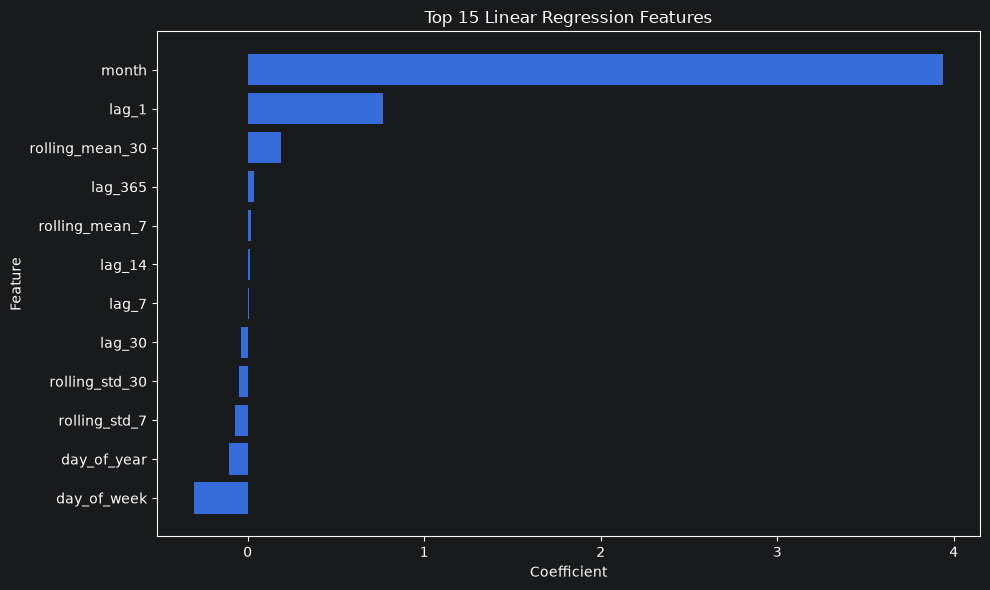

In [29]:
plt.figure(figsize=(10, 6))

top_features = linear_coefficients.head(15).sort_values(
    "Coefficient"
)

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Linear Regression Features")

plt.tight_layout()
plt.show()

In [30]:
# ============================================
# 15.1 RANDOM FOREST FEATURE IMPORTANCE
# ============================================

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)

print("Top 15 Random Forest Features:")
print(rf_importance.head(15))

Top 15 Random Forest Features:
            Feature  Importance
0             lag_1    0.843798
5    rolling_mean_7    0.026312
4           lag_365    0.017686
7     rolling_std_7    0.016592
2            lag_14    0.016243
8    rolling_std_30    0.016242
11      day_of_year    0.015563
1             lag_7    0.013586
3            lag_30    0.012703
6   rolling_mean_30    0.012487
10      day_of_week    0.006495
9             month    0.002293


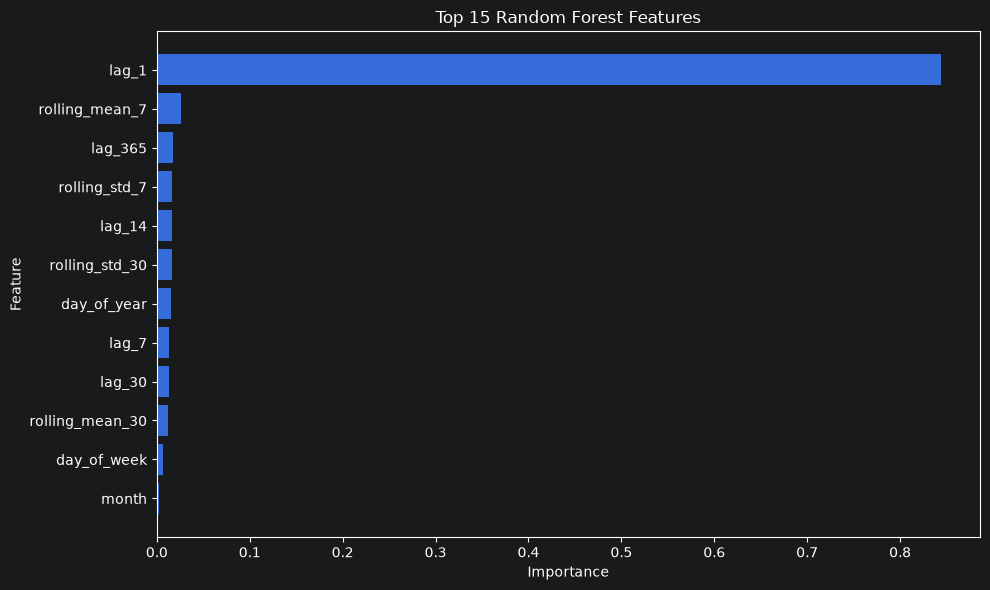

In [31]:
plt.figure(figsize=(10, 6))

top_rf = rf_importance.head(15).sort_values(
    "Importance"
)

plt.barh(
    top_rf["Feature"],
    top_rf["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Random Forest Features")

plt.tight_layout()
plt.show()

In [32]:
# ============================================
# 16.1 XGBOOST FEATURE IMPORTANCE
# ============================================

xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    "Importance",
    ascending=False
)

print("Top 15 XGBoost Features:")
print(xgb_importance.head(15))

Top 15 XGBoost Features:
            Feature  Importance
0             lag_1    0.458657
5    rolling_mean_7    0.234716
9             month    0.049012
11      day_of_year    0.040826
8    rolling_std_30    0.036195
7     rolling_std_7    0.030593
6   rolling_mean_30    0.030009
4           lag_365    0.029678
2            lag_14    0.024230
10      day_of_week    0.023650
3            lag_30    0.022687
1             lag_7    0.019747


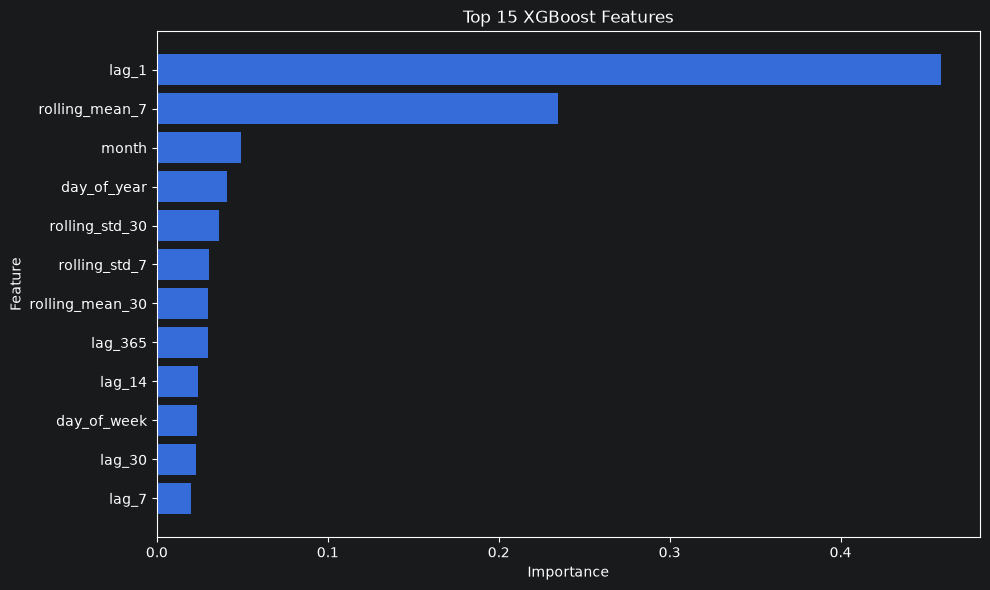

In [33]:
plt.figure(figsize=(10, 6))

top_xgb = xgb_importance.head(15).sort_values(
    "Importance"
)

plt.barh(
    top_xgb["Feature"],
    top_xgb["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Features")

plt.tight_layout()
plt.show()

In [34]:
# ============================================
# 17. VALIDATION MODEL COMPARISON
# ============================================

ml_validation_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": 34.092489,
        "RMSE": 46.872868,
        "MAPE": 15.966136
    },
    {
        "Model": "Random Forest",
        "MAE": 35.677709,
        "RMSE": 49.092308,
        "MAPE": 16.969363
    },
    {
        "Model": "XGBoost",
        "MAE": 36.844652,
        "RMSE": 50.267831,
        "MAPE": 17.729354
    }
])

ml_validation_results = ml_validation_results.sort_values(
    "MAE"
).reset_index(drop=True)

ml_validation_results

,Model,MAE,RMSE,MAPE
0,Linear Regression,34.092489,46.872868,15.966136
1,Random Forest,35.677709,49.092308,16.969363
2,XGBoost,36.844652,50.267831,17.729354


In [35]:
# ============================================
# 18. STATISTICAL VS ML VALIDATION
# ============================================

validation_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Category": "Machine Learning",
        "MAE": 34.092489,
        "RMSE": 46.872868,
        "MAPE": 15.966136
    },
    {
        "Model": "Random Forest",
        "Category": "Machine Learning",
        "MAE": 35.677709,
        "RMSE": 49.092308,
        "MAPE": 16.969363
    },
    {
        "Model": "XGBoost",
        "Category": "Machine Learning",
        "MAE": 36.844652,
        "RMSE": 50.267831,
        "MAPE": 17.729354
    },
    {
        "Model": "Seasonal Naive",
        "Category": "Statistical Baseline",
        "MAE": 66.387945,
        "RMSE": 88.689442,
        "MAPE": 32.316794
    },
    {
        "Model": "ARIMA(2,0,2)",
        "Category": "Statistical",
        "MAE": 90.394255,
        "RMSE": 105.990094,
        "MAPE": 50.647020
    },
    {
        "Model": "Naive",
        "Category": "Statistical Baseline",
        "MAE": 135.084932,
        "RMSE": 173.624362,
        "MAPE": 46.632066
    }
])

validation_comparison = validation_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

validation_comparison

,Model,Category,MAE,RMSE,MAPE
0,Linear Regression,Machine Learning,34.092489,46.872868,15.966136
1,Random Forest,Machine Learning,35.677709,49.092308,16.969363
2,XGBoost,Machine Learning,36.844652,50.267831,17.729354
3,Seasonal Naive,Statistical Baseline,66.387945,88.689442,32.316794
4,"ARIMA(2,0,2)",Statistical,90.394255,105.990094,50.647020
5,Naive,Statistical Baseline,135.084932,173.624362,46.632066


## 19. Recursive Multi-Step Forecasting

For a realistic forecasting scenario, future AQI values are unknown.

Therefore, after predicting one day, the prediction is fed back into the historical sequence and is used to construct lag and rolling features for the next day.

This prevents future actual AQI values from leaking into the forecast.

In [36]:
def recursive_forecast(
    model,
    history,
    forecast_dates,
    feature_columns
):

    history = history.copy()

    predictions = []

    for current_date in forecast_dates:

        # --------------------------------
        # Create features using available
        # historical information only
        # --------------------------------

        lag_1 = history.iloc[-1]["AQI"]

        lag_7 = history.iloc[-7]["AQI"]

        lag_14 = history.iloc[-14]["AQI"]

        lag_30 = history.iloc[-30]["AQI"]

        lag_365 = history.iloc[-365]["AQI"]

        rolling_mean_7 = (
            history["AQI"]
            .iloc[-7:]
            .mean()
        )

        rolling_mean_30 = (
            history["AQI"]
            .iloc[-30:]
            .mean()
        )

        rolling_std_7 = (
            history["AQI"]
            .iloc[-7:]
            .std()
        )

        rolling_std_30 = (
            history["AQI"]
            .iloc[-30:]
            .std()
        )

        month = current_date.month

        day_of_week = current_date.dayofweek

        day_of_year = current_date.dayofyear

        # --------------------------------
        # Construct feature row
        # --------------------------------

        feature_row = pd.DataFrame({
            "lag_1": [lag_1],
            "lag_7": [lag_7],
            "lag_14": [lag_14],
            "lag_30": [lag_30],
            "lag_365": [lag_365],
            "rolling_mean_7": [rolling_mean_7],
            "rolling_mean_30": [rolling_mean_30],
            "rolling_std_7": [rolling_std_7],
            "rolling_std_30": [rolling_std_30],
            "month": [month],
            "day_of_week": [day_of_week],
            "day_of_year": [day_of_year]
        })

        feature_row = feature_row[feature_columns]

        # --------------------------------
        # Predict next day
        # --------------------------------

        prediction = model.predict(
            feature_row
        )[0]

        predictions.append(prediction)

        # --------------------------------
        # Add prediction to history
        # --------------------------------

        new_row = pd.DataFrame(
            {"AQI": [prediction]},
            index=[current_date]
        )

        history = pd.concat([
            history,
            new_row
        ])

    return pd.Series(
        predictions,
        index=forecast_dates,
        name="Predicted_AQI"
    )

In [38]:
# ============================================
# 20.1 RECREATE TRAIN / VALIDATION / TEST
# ============================================

train = aqi.loc[
    "2015-01-01":"2018-07-02"
].copy()

validation = aqi.loc[
    "2018-07-03":"2019-07-02"
].copy()

test = aqi.loc[
    "2019-07-03":"2020-07-01"
].copy()

print("Training:", train.index.min(), "to", train.index.max())
print("Validation:", validation.index.min(), "to", validation.index.max())
print("Test:", test.index.min(), "to", test.index.max())

print("\nShapes:")
print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

Training: 2015-01-01 00:00:00 to 2018-07-02 00:00:00
Validation: 2018-07-03 00:00:00 to 2019-07-02 00:00:00
Test: 2019-07-03 00:00:00 to 2020-07-01 00:00:00

Shapes:
Train: (1279, 1)
Validation: (365, 1)
Test: (365, 1)


In [39]:
validation_dates = validation.index

In [40]:
linear_recursive_validation = recursive_forecast(
    model=lr_model,
    history=aqi.loc[:train_end],
    forecast_dates=validation_dates,
    feature_columns=feature_columns
)

In [41]:
print(linear_recursive_validation.head())

print()

print(linear_recursive_validation.tail())

Date
2018-07-03    130.670201
2018-07-04    148.175865
2018-07-05    163.592012
2018-07-06    171.385320
2018-07-07    176.106273
Name: Predicted_AQI, dtype: float64

Date
2019-06-28    336.928671
2019-06-29    333.466963
2019-06-30    331.091867
2019-07-01    334.322783
2019-07-02    336.540554
Name: Predicted_AQI, dtype: float64


In [42]:
linear_recursive_metrics = evaluate_ml_model(
    y_validation,
    linear_recursive_validation
)

linear_recursive_metrics

{'MAE': 96.87951172205481,
 'RMSE': np.float64(114.76593421339145),
 'MAPE': np.float64(57.42736220063892)}

In [43]:
rf_recursive_validation = recursive_forecast(
    model=rf_model,
    history=aqi.loc[:train_end],
    forecast_dates=validation.index,
    feature_columns=feature_columns
)

In [44]:
rf_recursive_metrics = evaluate_ml_model(
    y_validation,
    rf_recursive_validation
)

rf_recursive_metrics

{'MAE': 59.65601050459209,
 'RMSE': np.float64(76.27445494440559),
 'MAPE': np.float64(28.54805579668611)}

In [45]:
xgb_recursive_validation = recursive_forecast(
    model=xgb_model,
    history=aqi.loc[:train_end],
    forecast_dates=validation.index,
    feature_columns=feature_columns
)

In [46]:
xgb_recursive_metrics = evaluate_ml_model(
    y_validation,
    xgb_recursive_validation
)

xgb_recursive_metrics

{'MAE': 59.79027549012066,
 'RMSE': np.float64(77.16698773338507),
 'MAPE': np.float64(30.659162146457327)}

In [47]:
recursive_ml_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": linear_recursive_metrics["MAE"],
        "RMSE": linear_recursive_metrics["RMSE"],
        "MAPE": linear_recursive_metrics["MAPE"]
    },
    {
        "Model": "Random Forest",
        "MAE": rf_recursive_metrics["MAE"],
        "RMSE": rf_recursive_metrics["RMSE"],
        "MAPE": rf_recursive_metrics["MAPE"]
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_recursive_metrics["MAE"],
        "RMSE": xgb_recursive_metrics["RMSE"],
        "MAPE": xgb_recursive_metrics["MAPE"]
    }
])

recursive_ml_results = recursive_ml_results.sort_values(
    "MAE"
).reset_index(drop=True)

recursive_ml_results

,Model,MAE,RMSE,MAPE
0,Random Forest,59.656011,76.274455,28.548056
1,XGBoost,59.790275,77.166988,30.659162
2,Linear Regression,96.879512,114.765934,57.427362


In [48]:
best_ml_model_name = recursive_ml_results.iloc[0]["Model"]

print("Best ML model:", best_ml_model_name)

Best ML model: Random Forest


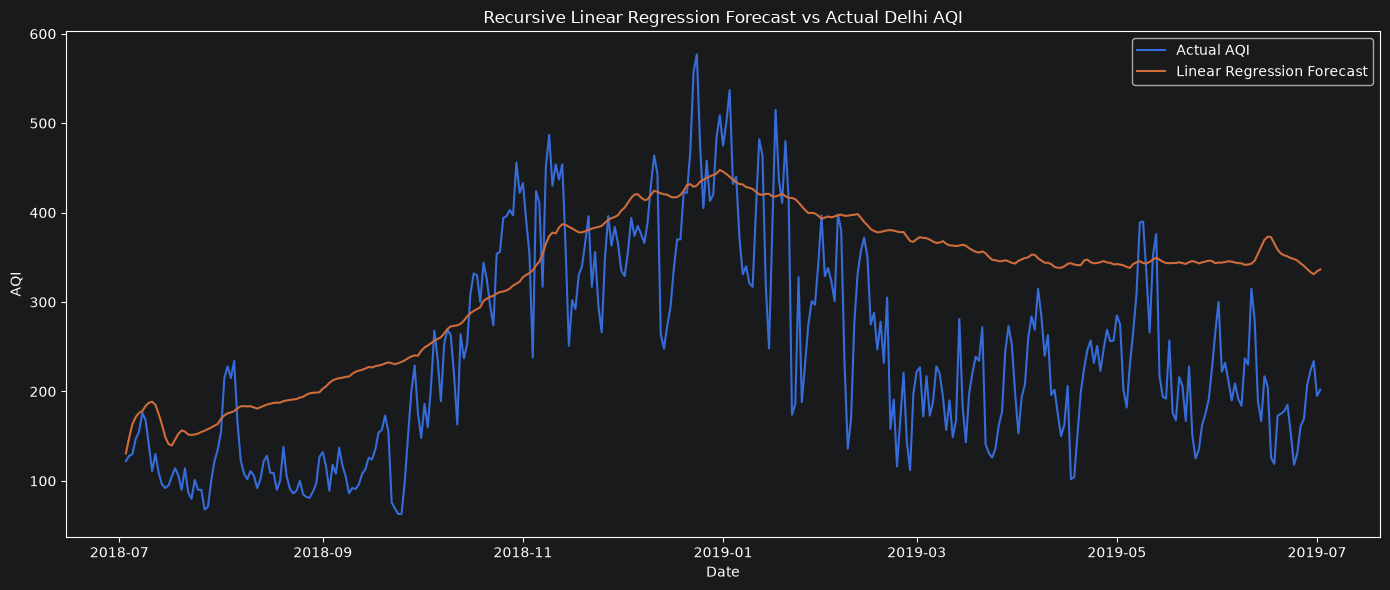

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_validation.index,
    y_validation,
    label="Actual AQI"
)

plt.plot(
    linear_recursive_validation.index,
    linear_recursive_validation,
    label="Linear Regression Forecast"
)

plt.title(
    "Recursive Linear Regression Forecast vs Actual Delhi AQI"
)

plt.xlabel("Date")
plt.ylabel("AQI")

plt.legend()

plt.tight_layout()
plt.show()

In [50]:
# ============================================
# 26.1 COMBINE TRAIN + VALIDATION
# ============================================

train_validation = pd.concat([
    train,
    validation
])

print(
    "Training period:",
    train_validation.index.min(),
    "to",
    train_validation.index.max()
)

print("Shape:", train_validation.shape)

Training period: 2015-01-01 00:00:00 to 2019-07-02 00:00:00
Shape: (1644, 1)


In [51]:
train_validation_features = create_features(
    train_validation
)

train_validation_features = (
    train_validation_features.dropna()
)

X_train_final = train_validation_features[
    feature_columns
]

y_train_final = train_validation_features[
    "AQI"
]

print("Final ML training shape:", X_train_final.shape)
print("Final target shape:", y_train_final.shape)

Final ML training shape: (1279, 12)
Final target shape: (1279,)


In [52]:
# ============================================
# 27. FINAL RANDOM FOREST MODEL
# ============================================

final_rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_rf_model.fit(
    X_train_final,
    y_train_final
)

print("Final Random Forest trained successfully.")

Final Random Forest trained successfully.


In [53]:
# ============================================
# 28. FINAL TEST FORECAST
# ============================================

final_rf_forecast = recursive_forecast(
    model=final_rf_model,
    history=train_validation.copy(),
    forecast_dates=test.index,
    feature_columns=feature_columns
)

print("First 10 predictions:")
print(final_rf_forecast.head(10))

print("\nLast 10 predictions:")
print(final_rf_forecast.tail(10))

First 10 predictions:
Date
2019-07-03    194.405301
2019-07-04    195.561954
2019-07-05    208.625516
2019-07-06    216.470534
2019-07-07    234.120272
2019-07-08    253.145626
2019-07-09    256.292149
2019-07-10    253.363837
2019-07-11    255.186199
2019-07-12    257.373206
Name: Predicted_AQI, dtype: float64

Last 10 predictions:
Date
2020-06-22    262.180983
2020-06-23    255.861583
2020-06-24    253.471946
2020-06-25    254.006971
2020-06-26    251.767930
2020-06-27    253.617790
2020-06-28    252.368354
2020-06-29    256.853225
2020-06-30    261.945117
2020-07-01    263.754301
Name: Predicted_AQI, dtype: float64


In [55]:
# ============================================
# EVALUATION FUNCTION
# ============================================

import numpy as np

def evaluate_forecast(actual, predicted):
    """
    Calculate MAE, RMSE and MAPE.
    """

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    # Remove any missing values
    mask = np.isfinite(actual) & np.isfinite(predicted)

    actual = actual[mask]
    predicted = predicted[mask]

    mae = np.mean(np.abs(actual - predicted))

    rmse = np.sqrt(
        np.mean((actual - predicted) ** 2)
    )

    # Avoid division by zero in MAPE
    non_zero = actual != 0

    mape = np.mean(
        np.abs(
            (actual[non_zero] - predicted[non_zero])
            / actual[non_zero]
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

In [56]:
# ============================================
# 29. FINAL RANDOM FOREST METRICS
# ============================================

final_rf_metrics = evaluate_forecast(
    test["AQI"],
    final_rf_forecast
)

final_rf_metrics

{'MAE': np.float64(110.9156343533417),
 'RMSE': np.float64(125.61368641860363),
 'MAPE': np.float64(88.3239926512759)}

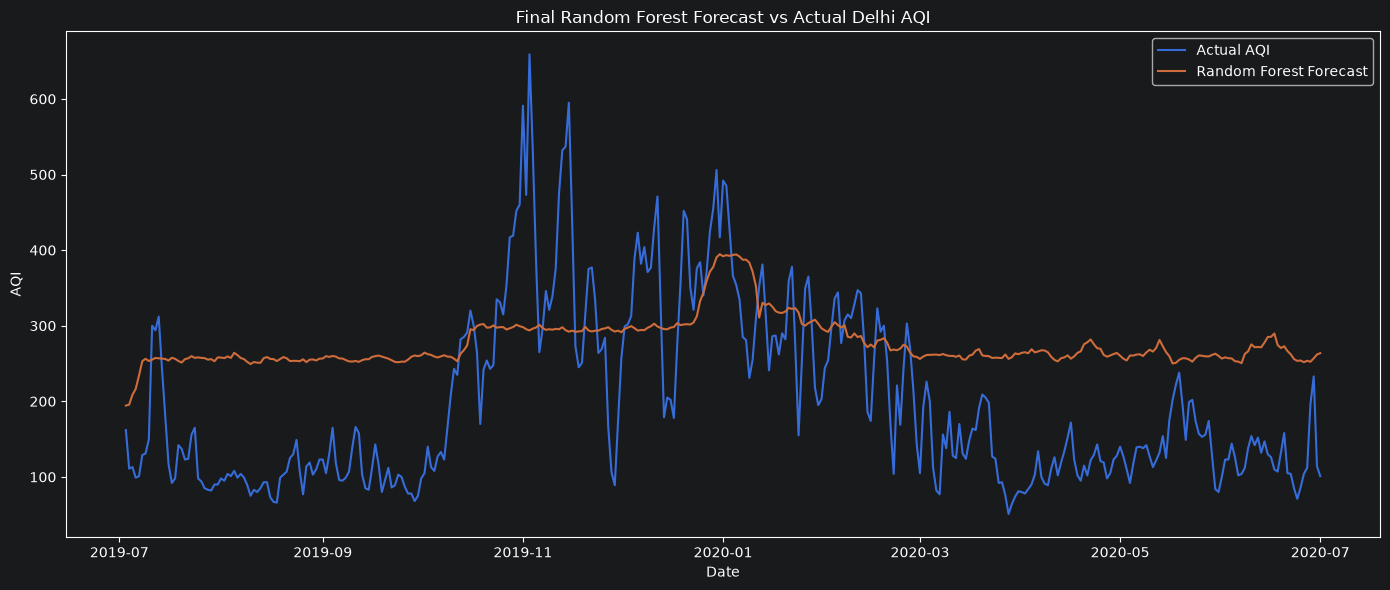

In [57]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    final_rf_forecast.index,
    final_rf_forecast,
    label="Random Forest Forecast"
)

plt.title(
    "Final Random Forest Forecast vs Actual Delhi AQI"
)

plt.xlabel("Date")
plt.ylabel("AQI")

plt.legend()

plt.tight_layout()

plt.show()

In [58]:
final_ml_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": final_rf_metrics["MAE"],
        "RMSE": final_rf_metrics["RMSE"],
        "MAPE": final_rf_metrics["MAPE"]
    }
])

final_ml_results

,Model,MAE,RMSE,MAPE
0,Random Forest,110.915634,125.613686,88.323993


In [59]:
final_rf_output = pd.DataFrame({
    "Date": test.index,
    "Actual_AQI": test["AQI"].values,
    "Predicted_AQI": final_rf_forecast.values
})

final_rf_output.to_csv(
    "../outputs/forecasts/final_random_forest_forecast.csv",
    index=False
)

print(
    "Saved:",
    "../outputs/forecasts/final_random_forest_forecast.csv"
)

Saved: ../outputs/forecasts/final_random_forest_forecast.csv


In [60]:
final_ml_results.to_csv(
    "../outputs/final_random_forest_results.csv",
    index=False
)

print("Final Random Forest results saved.")

Final Random Forest results saved.


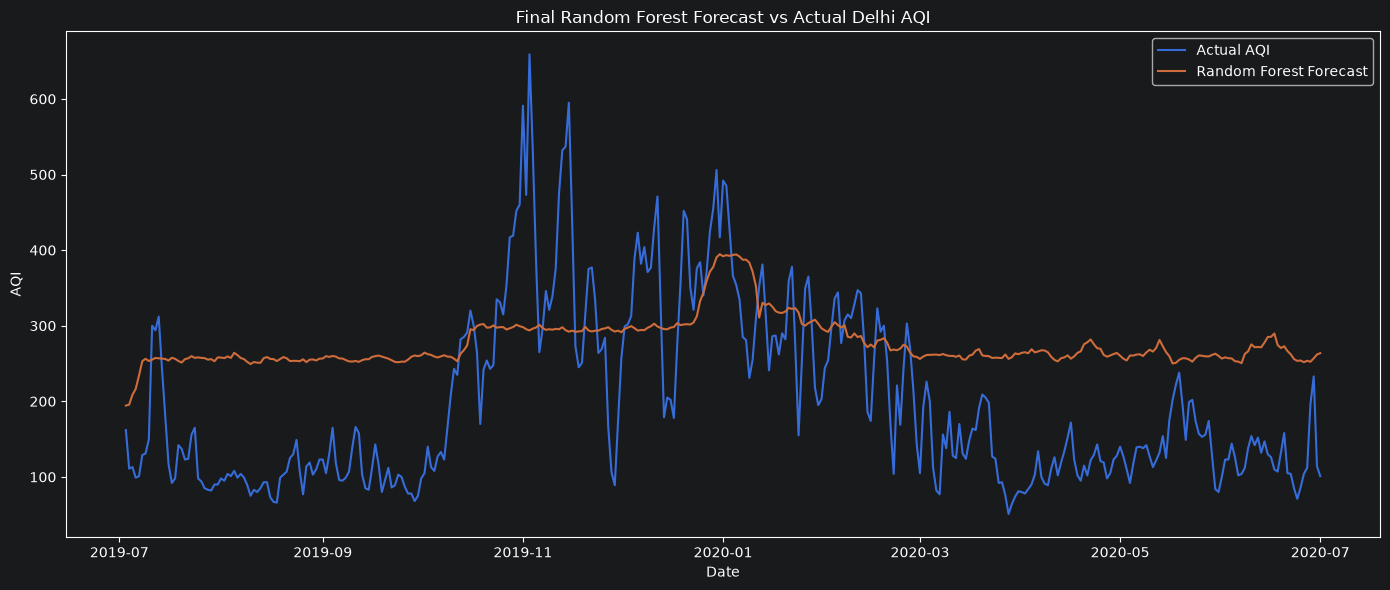

In [61]:
# ============================================
# 30. FINAL RANDOM FOREST FORECAST PLOT
# ============================================

plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test["AQI"],
    label="Actual AQI"
)

plt.plot(
    final_rf_forecast.index,
    final_rf_forecast,
    label="Random Forest Forecast"
)

plt.title("Final Random Forest Forecast vs Actual Delhi AQI")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()

plt.tight_layout()
plt.show()

In [62]:
# ============================================
# 31. FINAL ML RESULTS
# ============================================

final_ml_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": final_rf_metrics["MAE"],
        "RMSE": final_rf_metrics["RMSE"],
        "MAPE": final_rf_metrics["MAPE"]
    }
])

final_ml_results

,Model,MAE,RMSE,MAPE
0,Random Forest,110.915634,125.613686,88.323993


In [63]:
# ============================================
# 32. FINAL MODEL COMPARISON
# ============================================

final_model_comparison = pd.DataFrame([
    {
        "Model": "Naive",
        "Category": "Statistical Baseline",
        "MAE": 99.013699,
        "RMSE": 118.178110,
        "MAPE": 62.695832
    },
    {
        "Model": "Seasonal Naive",
        "Category": "Statistical Baseline",
        "MAE": 75.619178,
        "RMSE": 98.415822,
        "MAPE": 51.659498
    },
    {
        "Model": "ARIMA(2,0,2)",
        "Category": "Statistical",
        "MAE": 114.198056,
        "RMSE": 128.918109,
        "MAPE": 86.160062
    },
    {
        "Model": "SARIMA(1,0,1)(1,0,1,7)",
        "Category": "Statistical",
        "MAE": 173.668410,
        "RMSE": 215.356767,
        "MAPE": 80.460293
    },
    {
        "Model": "Fourier + ARIMA(2,0,2)",
        "Category": "Statistical",
        "MAE": 73.432871,
        "RMSE": 93.702537,
        "MAPE": 51.061704
    },
    {
        "Model": "Random Forest",
        "Category": "Machine Learning",
        "MAE": final_rf_metrics["MAE"],
        "RMSE": final_rf_metrics["RMSE"],
        "MAPE": final_rf_metrics["MAPE"]
    }
])

final_model_comparison = final_model_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

final_model_comparison

,Model,Category,MAE,RMSE,MAPE
0,"Fourier + ARIMA(2,0,2)",Statistical,73.432871,93.702537,51.061704
1,Seasonal Naive,Statistical Baseline,75.619178,98.415822,51.659498
2,Naive,Statistical Baseline,99.013699,118.178110,62.695832
3,Random Forest,Machine Learning,110.915634,125.613686,88.323993
4,"ARIMA(2,0,2)",Statistical,114.198056,128.918109,86.160062
5,"SARIMA(1,0,1)(1,0,1,7)",Statistical,173.668410,215.356767,80.460293


In [64]:
# ============================================
# 33. OVERALL BEST MODEL
# ============================================

best_model = final_model_comparison.loc[
    final_model_comparison["MAE"].idxmin()
]

print("Best Overall Model")
print("------------------")
print("Model:", best_model["Model"])
print("Category:", best_model["Category"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("MAPE:", best_model["MAPE"])

Best Overall Model
------------------
Model: Fourier + ARIMA(2,0,2)
Category: Statistical
MAE: 73.432871
RMSE: 93.702537
MAPE: 51.061704


In [65]:
# ============================================
# 34. SAVE FINAL MODEL COMPARISON
# ============================================

final_model_comparison.to_csv(
    "../outputs/final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully.")

Final model comparison saved successfully.


In [66]:
# ============================================
# 35. SAVE RANDOM FOREST FORECAST
# ============================================

final_rf_output = pd.DataFrame({
    "Date": test.index,
    "Actual_AQI": test["AQI"].values,
    "Predicted_AQI": final_rf_forecast.values
})

final_rf_output.to_csv(
    "../outputs/forecasts/final_random_forest_forecast.csv",
    index=False
)

print("Random Forest forecast saved successfully.")

Random Forest forecast saved successfully.


In [67]:
# ============================================
# 36. SAVE FINAL ML METRICS
# ============================================

final_ml_results.to_csv(
    "../outputs/final_random_forest_results.csv",
    index=False
)

print("Random Forest metrics saved successfully.")

Random Forest metrics saved successfully.


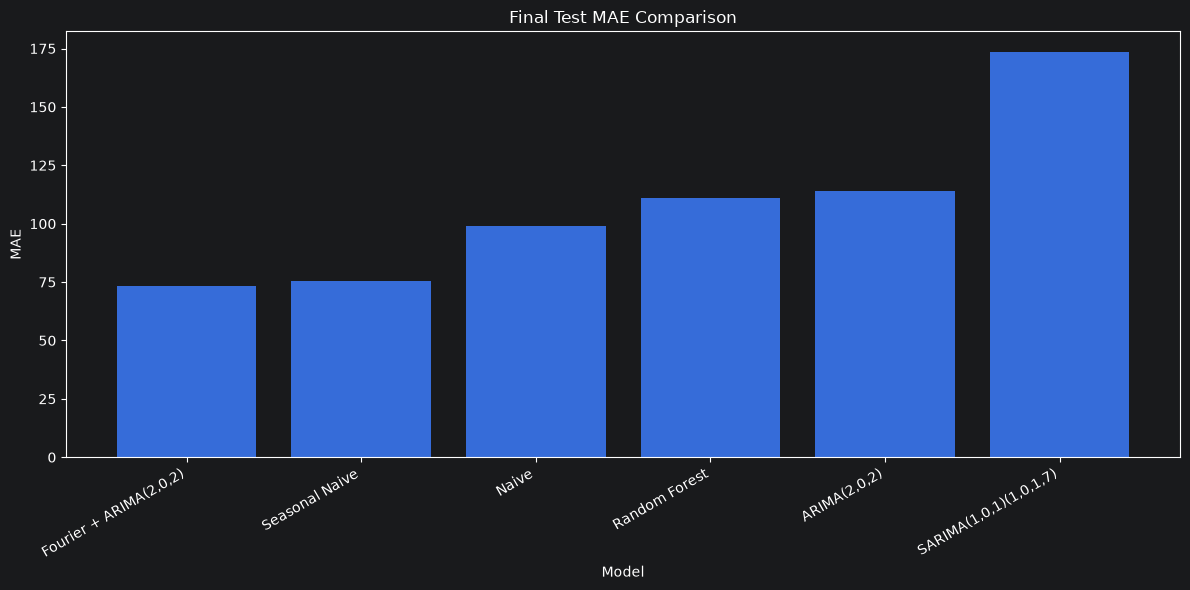

In [68]:
# ============================================
# 37. FINAL MODEL COMPARISON PLOT
# ============================================

plt.figure(figsize=(12, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["MAE"]
)

plt.ylabel("MAE")
plt.xlabel("Model")
plt.title("Final Test MAE Comparison")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

# Final Machine Learning Results

Machine-learning models were evaluated using a chronological forecasting framework.

Models evaluated:

- Linear Regression
- Random Forest
- XGBoost

Feature engineering included:

- Lag features
- Rolling mean features
- Rolling standard deviation features
- Calendar features
- Annual lag

Initial validation showed that Linear Regression achieved the lowest error when evaluated using directly available validation features. However, under recursive multi-step forecasting, Random Forest was selected as the best-performing ML model.

The final Random Forest model was retrained using the combined training and validation data and evaluated on the completely unseen final test period from 2019-07-03 to 2020-07-01.

The final ML results were compared with:

- Naive Forecast
- Seasonal Naive Forecast
- ARIMA
- SARIMA
- Fourier + ARIMA

The final model comparison is stored in:

`outputs/final_model_comparison.csv`

The Random Forest forecast is stored in:

`outputs/forecasts/final_random_forest_forecast.csv`